In [1]:
import torch
from torch import nn
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math

torch.manual_seed(42)

train = datasets.FashionMNIST(root="../data", train=True, download=True, transform=ToTensor())

train_loader = DataLoader(train, batch_size=64, shuffle=True)
xb, yb = next(iter(train_loader))

assert xb.shape == (64,1,28,28)
assert yb.shape == (64,)

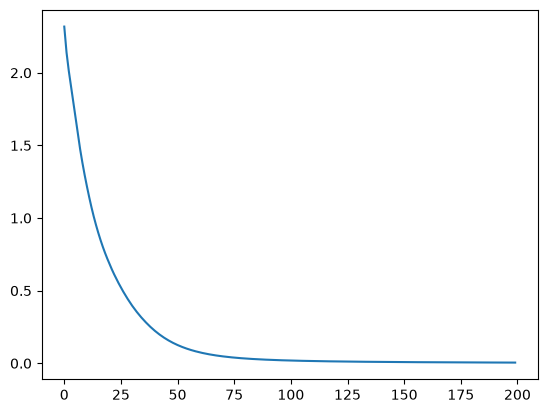

In [2]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(784, 128)
        self.out = nn.Linear(128, 10)
    def forward(self, x):
        h = torch.relu(self.hidden(x.reshape(len(x), -1)))
        return self.out(h)

model = MLP()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

losses = []

for _ in range(200):
    optimizer.zero_grad()
    loss = loss_fn(model(xb), yb)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

plt.plot(losses)
plt.show()

assert abs(losses[0] - math.log(10)) < 0.2
assert abs(losses[-1]) < 0.01

with torch.no_grad():
    assert sum(model(xb).argmax(dim=1) == yb) == 64

In [3]:
goodModel = MLP()
with torch.no_grad():
    scores = goodModel(xb)

    print(scores[0])
    print(scores.min())
    print(scores.max())

tensor([ 0.1038, -0.0995, -0.1835, -0.1000,  0.1048,  0.0754, -0.0550, -0.0349,
         0.0562,  0.0843])
tensor(-0.5235)
tensor(0.2347)


In [4]:
badModel = MLP()
with torch.no_grad():
    badModel.out.weight *= 50
    scores = badModel(xb)
    print(scores.min())
    print(scores.max())
    print(loss_fn(badModel(xb), yb))

tensor(-16.8151)
tensor(13.3299)
tensor(5.7116)


In [5]:
def train(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()

    losses = []

    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    return losses

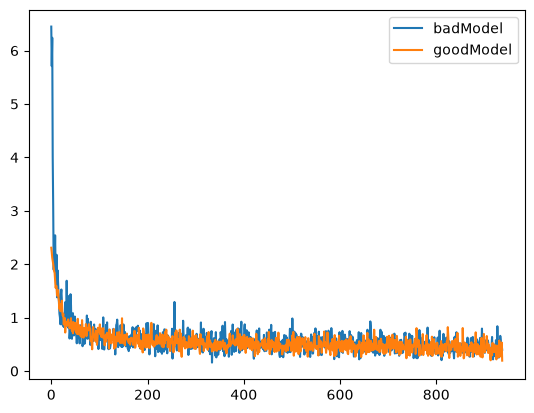

In [6]:
badLosses = train(badModel)
goodLosses = train(goodModel)

plt.plot(badLosses, label = "badModel")
plt.plot(goodLosses, label = "goodModel")
plt.legend()
plt.show()



In [7]:
meanLastBad = sum(badLosses[-100:]) / 100
meanLastGood = sum(goodLosses[-100:]) / 100

print(meanLastBad)
print(meanLastGood)

0.46207039266824723
0.41806653067469596


In [8]:
assert abs(goodLosses[0] - math.log(10)) < 0.2
assert badLosses[0] > 2 * goodLosses[0]
assert abs(meanLastBad - meanLastGood) < 0.1